# 🔵1) downloads and imports

### 🟠1.1) download stable-diffusion-2-base

In [4]:
# if needed 
#!pip install --upgrade diffusers transformers accelerate scipy safetensors

In [5]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


In [5]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


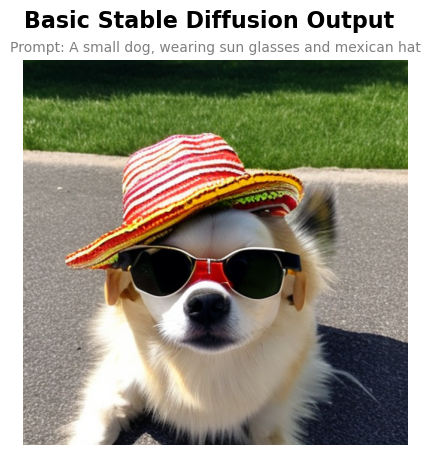

In [6]:
# show image generated
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("basic_stable_deffusion_check.png")

plt.figure(figsize=(5, 5)) 

plt.imshow(img) 
plt.axis("off") 

plt.suptitle("Basic Stable Diffusion Output", fontsize=16, fontweight='bold')
plt.title("Prompt: A small dog, wearing sun glasses and mexican hat", fontsize=10, color='gray')

plt.show() 

In [10]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler
from PIL import Image

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(
    model_id,
    subfolder="scheduler"
)

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    scheduler=scheduler,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sunglasses and mexican hat with the face of the dog in high resolution"

# number of diffusion steps
num_steps = 50

# store images
saved_images = []


# -----------------------------------
# Callback - called after each step
# -----------------------------------

def callback_on_step_end(pipe, step_index, timestep, callback_kwargs):

    # Save every 4 steps
    if step_index % 10 == 0:

        latents = callback_kwargs["latents"]

        # VAE expects scaled latents
        latents_for_decode = latents / pipe.vae.config.scaling_factor

        with torch.no_grad():
            image = pipe.vae.decode(latents_for_decode).sample

        # Convert [-1,1] -> [0,1]
        image = (image / 2 + 0.5).clamp(0, 1)

        # [B,C,H,W] -> [B,H,W,C]
        image = image[0].permute(1, 2, 0)

        # tensor -> numpy -> PIL
        image = (image * 255).round().to(torch.uint8).cpu().numpy()

        image = Image.fromarray(image)

        filename = f"diffusion_step_{step_index:02d}.png"
        image.save(filename)

        print(f"Saved {filename}")

    return callback_kwargs


# -----------------------------------
# Run diffusion
# -----------------------------------

result = pipe(
    prompt,
    num_inference_steps=num_steps,
    callback_on_step_end=callback_on_step_end,
    callback_on_step_end_tensor_inputs=["latents"]
)

# final image
result.images[0].save("final.png")

print("Done!")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Saved diffusion_step_00.png
Saved diffusion_step_10.png
Saved diffusion_step_20.png
Saved diffusion_step_30.png
Saved diffusion_step_40.png
Done!


# 🔵2) implementing the base Inpainting, based on the papers

### 🟠2.1) creating the vanila inpainting logic 

* now, to achive the impanting described in the paper, we cant just use a similar pipe as we have difined before, we must have control over the epocs of the denoising process. thus: 

#### 🟢2.1.1) first, we create some healper functions

* as we have learned in class, writen in the stable-diffusion-2-base repository, and wrriten in the original paper, Stable Diffusion operates within a compressed latent space using a **Variational Autoencoder (VAE)**.
* Therefore, if we want to create the base impainting idia, we need to have a way to transform the imput image, and the given mask, to their representations in the VAE space, thus we have created those functions.
* Since the VAE encoder utilizes convolutional operations that **preserve spatial structure**, the resized mask spatially aligns with the latent representation of the image. This alignment allows us to perform the blending operations directly within the latent space, which is crucial for our impainting implementation.
* להוסיף על הטקסט

In [63]:
def preprocess_image(image):
    """
    Helper function to convert PIL image to Tensor in range [-1, 1]
    """
    w, h = image.size
    w, h = map(lambda x: x - x % 32, (w, h))  # Resize to become divisible by 32
    image = image.resize((w, h), resample=PIL.Image.LANCZOS)
    image = np.array(image).astype(np.float32) / 255.0
    image = image[None].transpose(0, 3, 1, 2) # (Batch, Channel, Height, Width)
    image = torch.from_numpy(image)
    return 2.0 * image - 1.0

def encode_image_to_latents(pipe, image, device):
    """
    Encodes a PIL image into Stable Diffusion latents using the VAE.
    """
    image_tensor = preprocess_image(image).to(device).half()
    
    with torch.no_grad():
        latents = pipe.vae.encode(image_tensor).latent_dist.sample()
        latents = latents * 0.18215
    return latents

def get_text_embeddings(pipe, prompt, negative_prompt, device):
    text_input = pipe.tokenizer(
        prompt, 
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]

    uncond_input = pipe.tokenizer(
        negative_prompt,  
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    uncond_embeddings = pipe.text_encoder(uncond_input.input_ids.to(device))[0]

    text_embeddings = torch.cat([uncond_embeddings, text_embeddings])
    return text_embeddings
    

#### 🟢2.1.2) now, we can create inpanting logic

להוסיף הסבר על המתמטיקה ומה בפועל אנחנו עושים פה עם התרשים שיצרתי 

In [64]:
import torch
import torch.nn.functional as F
import numpy as np
import PIL
from tqdm.auto import tqdm


def vanilla_inpainting(pipe, prompt, negative_prompt, init_image, mask_image, seed = None, steps=50, guidance_scale=7):
    """
    Custom loop for Inpainting using a standard Text-to-Image model.
    
    Args:
        pipe: The StableDiffusionPipeline 
        prompt: Text description.
        init_image: The original PIL image.
        mask_image: The mask PIL image (White = Inpaint, Black = Keep).
    """
    
    device = pipe.device
    height, width = init_image.size
    if seed != None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    #use our functions to move to the latent space, and to embed the given text
    init_latents = encode_image_to_latents(pipe, init_image, device)
    text_embeddings = get_text_embeddings(pipe, prompt, negative_prompt, device)

    mask = np.array(mask_image.convert("L")).astype(np.float32) / 255.0
    mask = torch.from_numpy(mask)[None, None].to(device).half()
    mask = F.interpolate(mask, size=(height // 8, width // 8), mode="nearest")

    #initielize the noise
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn((1, 4, height // 8, width // 8), generator=generator, device=device, dtype=torch.float16)
    latents = latents * pipe.scheduler.init_noise_sigma
    
    # main loop
    print("Running Inpainting Loop...")
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps)):

        # first, we take the latent representation of the original image, apply to it noise, just like it sould have been in step num t.
        if i < len(pipe.scheduler.timesteps) - 1:
            next_t = pipe.scheduler.timesteps[i + 1] # זהו שלב ה-t-1 האמיתי
            noise = torch.randn_like(init_latents)
            latents_original_noisy = pipe.scheduler.add_noise(init_latents, noise, next_t.unsqueeze(0))
        else:
            latents_original_noisy = init_latents

        # We duplicate the latents (x2) to run two parallel predictions in one batch: 
        # one with the text prompt (conditional) and one without (unconditional/empty) for Guidance.
        latent_model_input = torch.cat([latents] * 2)
        latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

        # now, we get the grediction given the step we are in
        with torch.no_grad():
            noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # We split the result back into two: 
        # 1. noise_pred_uncond: what the model thinks based on NO text.
        # 2. noise_pred_text: what the model thinks based on text.
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)

        # we apply the Guidance formula: we push the result away from the "unconditional" guess towards the "text" guess.
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # We take the predicted noise and subtract it from the current latents using the scheduler's math.
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample

        #now, we apply the actual basic inpanting logic. 
        #in the areas in the latent space that does not coresponds with the mask, we takt the noisy original image of step t. 
        #otherwise, we take the generated image 
        latents = (mask * latents) + ((1 - mask) * latents_original_noisy)
    
    # final decode from the latent space to the image space
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    # final manipulation
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

#### 🟢2.1.3) runing and testing the inpanting we have made

In [126]:
def generate_15_images(inpainting ,pipe, prompt, negative_prompt, current_seed, init_image, mask_image, **args):
    #create 15 images in 15 different seeds to test the metodology
    num_images = 15
    generated_images = []
    print(f"Generating {num_images} variations...")
    
    #create the images using the model
    for i in range(num_images):
        current_seed = base_seed + i
        print(f"Generating image {i+1}/{num_images} with seed {current_seed}...")
        
        result = inpainting(
            pipe=pipe,
            prompt=prompt,
            negative_prompt=negative_prompt,
            seed=current_seed,
            init_image=init_image,
            mask_image=mask_image,
            **args,
        )
        generated_images.append({'seed': current_seed, 'image': result})
    
    #presenting the images (this code was generated buy the chat)
    fig = plt.figure(figsize=(20, 15))
    
    ax_orig = plt.subplot2grid((5, 10), (0, 2), colspan=3, rowspan=1)
    ax_mask = plt.subplot2grid((5, 10), (0, 5), colspan=3, rowspan=1)
    
    ax_orig.imshow(init_image)
    ax_orig.set_title("Original Image", fontsize=16)
    ax_orig.axis("off")
    
    ax_mask.imshow(mask_image, cmap='gray')
    ax_mask.set_title("Mask Input", fontsize=16)
    ax_mask.axis("off")
    rows = 3
    cols = 5
    for i, item in enumerate(generated_images):
        row = (i // cols) + 1 
        col = (i % cols) * 2  
        ax = fig.add_subplot(4, 5, i + 6)
        
        ax.imshow(item['image'])
        ax.set_title(f"Seed: {item['seed']}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [100]:
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import DDPMScheduler
import math

#load the test image and mask
init_image_path = "empty_lake.png"
mask_image_path = "debug_mask.png"
init_image = Image.open(init_image_path).convert("RGB").resize((512, 512))
mask_image = Image.open(mask_image_path).convert("L").resize((512, 512))

prompt = "A highly detailed photograph of a small, weathered wooden rowboat floating on the calm mountain lake. The boat has peeling paint and old oars resting inside. Golden hour sunlight hits the side of the boat, casting a realistic reflection on the water surface. Cinematic lighting, photorealistic, 8k resolution."
negative_prompt = "cartoon, drawing, 3d render, plastic, blurred, low quality, illustration, painting, unreal engine, smooth"
seed = 100

#verifying we are using DPPM Scedualer
pipe.scheduler = DDPMScheduler.from_config(pipe.scheduler.config)

#generating 15 images, 
generate_15_images(vanilla_inpainting ,pipe, prompt, negative_prompt, seed, init_image, mask_image, steps=50)

Generating 15 variations...
Generating image 1/15 with seed 100...
Running Inpainting Loop...


  0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

### 🟠2.2) adding the RePaint logic from the paper

* We have added the RePaint logic to the vanilla inpainting in the following way:

* first, we run the exact same logic of one step of the vanila inpainting - 
 
* now, we apply a generalized resampling logic: If the current iteration is not the last jump for this timestep, we must revert the blended latent $x_{t-1}^{mixed}$ back to the noise level of $t$ to repeat the denoising process. Because we are using an arbitrary number of inference steps (in our case 50, but we can change it), we derive the exact signal retention ratio and variance matching mathematically.
According to the forward diffusion process, any latent state $x_t$ can be expressed in terms of the original uncorrupted image $x_0$ and pure noise $\epsilon \sim \mathcal{N}(0, I)$:
 
    $$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon$$
  Similarly, the latent at the previous step $t-1$ is:

    $$x_{t-1} = \sqrt{\bar{\alpha}_{t-1}} x_0 + \sqrt{1 - \bar{\alpha}_{t-1}} \epsilon'$$

    To step backwards from $t-1$ to $t$, we first scale $x_{t-1}$ by a constant $K$ so that its signal coefficient matches that of $x_t$:

  $$K \sqrt{\bar{\alpha}_{t-1}} = \sqrt{\bar{\alpha}_t} \implies K = \sqrt{\frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}}$$

  We define the ratio inside the square root as $c$:

  $$c = \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}$$

  Next, we must account for the noise variance. The target variance for the noise component at step $t$ is $1 - \bar{\alpha}_t$ (as shown in lecture 12).

  Scaling $x_{t-1}$ by $\sqrt{c}$ modifies its existing noise variance to $c(1 - \bar{\alpha}_{t-1})$. The missing variance $\sigma^2$ that we need to inject is the difference:

  $$\sigma^2 = (1 - \bar{\alpha}_t) - c(1 - \bar{\alpha}_{t-1})$$

  Substituting $c$:

  $$\sigma^2 = 1 - \bar{\alpha}_t - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}(1 - \bar{\alpha}_{t-1}) = 1 - \bar{\alpha}_t - \left( \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}} - \bar{\alpha}_t \right) = 1 - c$$

  By adding new standard Gaussian noise $z \sim \mathcal{N}(0, I)$ scaled by the standard deviation $\sqrt{1 - c}$, we can perfectly reconstruct the statistical distribution of step $t$:

  $$x_t^{jump} = \sqrt{c} x_{t-1}^{mixed} + \sqrt{1 - c} z$$


In [129]:
import torch
import torch.nn.functional as F
import numpy as np
import PIL
from tqdm.auto import tqdm
from diffusers import DDPMScheduler

def repaint_inpainting(pipe, prompt, negative_prompt, init_image, mask_image, seed=None, steps=100, guidance_scale=7, jumps=5, show_progress=True):
    device = pipe.device
    width, height = init_image.size
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)
        
    init_latents = encode_image_to_latents(pipe, init_image, device)
    text_embeddings = get_text_embeddings(pipe, prompt, negative_prompt, device)
    
    mask = np.array(mask_image.convert("L")).astype(np.float32) / 255.0
    mask = torch.from_numpy(mask)[None, None].to(device).half()
    mask = F.interpolate(mask, size=(height // 8, width // 8), mode="nearest")
    
    pipe.scheduler.set_timesteps(steps)
    timesteps = pipe.scheduler.timesteps

    latents = torch.randn((1, 4, height // 8, width // 8), generator=generator, device=device, dtype=torch.float16)
    latents = latents * pipe.scheduler.init_noise_sigma
    
    if show_progress:
        print(f"Running RePaint Loop with {jumps} jumps per step...")

    for i, t in enumerate(tqdm(timesteps, disable=not show_progress)):
        for u in range(jumps):
            latent_model_input = torch.cat([latents] * 2)
            latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

            with torch.no_grad():
                noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

            noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
            noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)
            
            step_output = pipe.scheduler.step(noise_pred, t, latents)
            latents_denoised = step_output.prev_sample 

            #now we apply the repaint logic. 
            #first, We add noise to the original uncorrupted image, match the noise level of the next timestep.
            if i < len(timesteps) - 1:
                next_t = timesteps[i + 1]
                noise_for_init = torch.randn(init_latents.shape, generator=generator, device=device, dtype=init_latents.dtype)
                init_latents_proper_noise = pipe.scheduler.add_noise(init_latents, noise_for_init, next_t)
            else:
                #in the last step, there is no need to add noise to the background...
                next_t = torch.tensor(0, device=device)
                init_latents_proper_noise = init_latents 
            
            #now, we blend the newly denoised latents (inside the mask) with the properly noised background (outside the mask)
            latents = (mask * latents_denoised) + ((1 - mask) * init_latents_proper_noise)

            is_last_jump = (u == jumps - 1)
            is_last_step = (i == len(timesteps) - 1)
            
            #if it is not the last jump step, we jump back in time from next_t to t, to "repaint" the image.
            if not is_last_jump and not is_last_step:
                #now, we apply the equation that was described before:
                alpha_t = pipe.scheduler.alphas_cumprod[t].to(device)
                alpha_next_t = pipe.scheduler.alphas_cumprod[next_t].to(device)
                
                #calculate the exact ratio of the image we need to keep
                ratio = alpha_t / alpha_next_t
                
                #inject new noise to make up for the remaining variance and push the latents back to timestep t
                noise_for_jump = torch.randn(latents.shape, generator=generator, device=device, dtype=latents.dtype)
                latents = torch.sqrt(ratio) * latents + torch.sqrt(1 - ratio) * noise_for_jump

    # Decode
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

Generating 15 variations...
Generating image 1/15 with seed 100...
Running RePaint Loop with 5 jumps per step...


  0%|          | 0/50 [00:00<?, ?it/s]

Generating image 2/15 with seed 101...
Running RePaint Loop with 5 jumps per step...


  0%|          | 0/50 [00:00<?, ?it/s]

Generating image 3/15 with seed 102...
Running RePaint Loop with 5 jumps per step...


...

Generating image 14/15 with seed 113...
Running RePaint Loop with 5 jumps per step...


  0%|          | 0/50 [00:00<?, ?it/s]

Generating image 15/15 with seed 114...
Running RePaint Loop with 5 jumps per step...


  0%|          | 0/50 [00:00<?, ?it/s]

/tmp/ipykernel_7100/3632182770.py:46: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


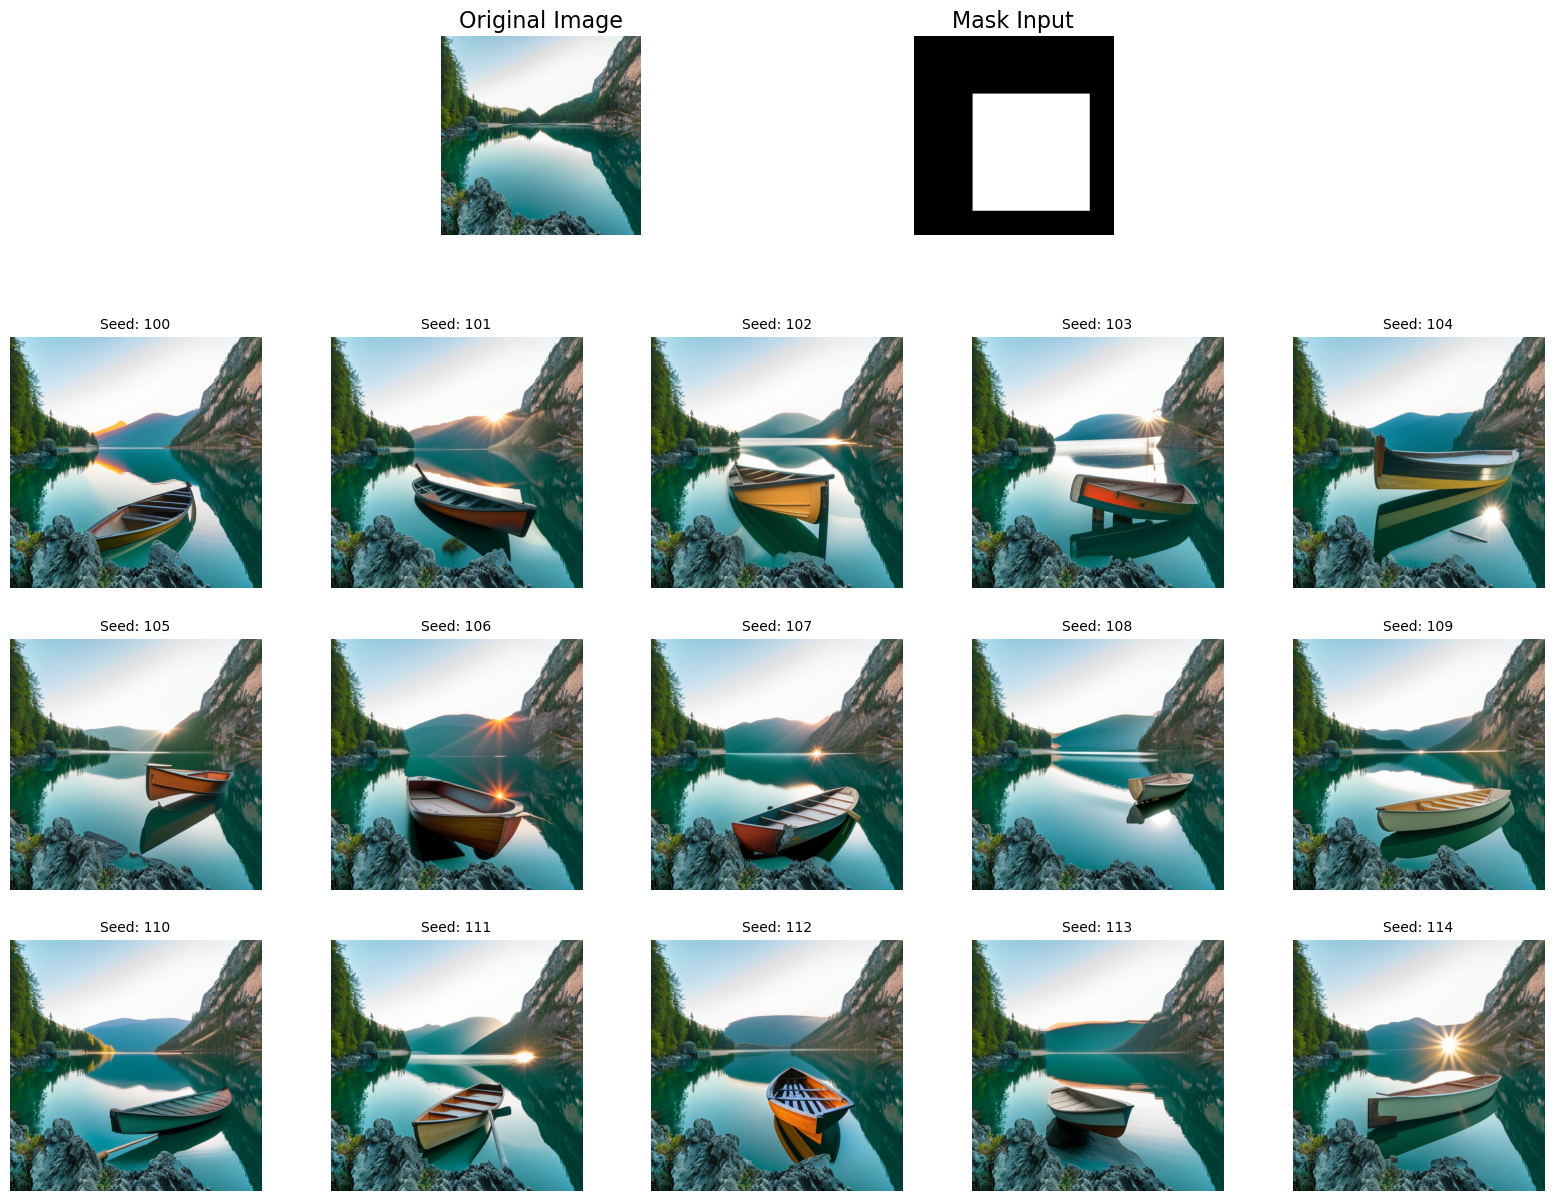

In [128]:
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import DDPMScheduler
import math

#load the test image and mask
init_image_path = "empty_lake.png"
mask_image_path = "debug_mask.png"
init_image = Image.open(init_image_path).convert("RGB").resize((512, 512))
mask_image = Image.open(mask_image_path).convert("L").resize((512, 512))

prompt = "A highly detailed photograph of a small, weathered wooden rowboat floating on the calm mountain lake. The boat has peeling paint and old oars resting inside. Golden hour sunlight hits the side of the boat, casting a realistic reflection on the water surface. Cinematic lighting, photorealistic, 8k resolution."
negative_prompt = "cartoon, drawing, 3d render, plastic, blurred, low quality, illustration, painting, unreal engine, smooth"
seed = 100

#verifying we are using DPPM Scedualer 
pipe.scheduler = DDPMScheduler.from_config(pipe.scheduler.config)

#generating 15 images 
generate_15_images(repaint_inpainting ,pipe, prompt, negative_prompt, seed, init_image, mask_image, steps=50, guidance_scale=7, jumps=5)

In [55]:
import os
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from PIL import Image, ImageDraw, ImageFont

def create_comparison_image(orig_img, generated_img, mask_img, img_name, method_name):
    """
    יוצרת תמונת רביעייה למחקר: 
    [מקור נקי] | גבול | [מקור עם מסיכה אדומה] | גבול | [תוצאה מג'ונרטת]
    כולל כיתוב ממורכז מעל כל חלק.
    """
    # 1. הכנת המקור עם המסיכה (אדום חצי שקוף)
    img_rgba = orig_img.convert("RGBA")
    red_overlay = Image.new("RGBA", img_rgba.size, (255, 0, 0, 128))
    source_with_mask = Image.composite(red_overlay, img_rgba, mask_img).convert("RGB")
    
    # 2. הגדרות מידות
    w, h = orig_img.size
    border_width = 10
    text_area_height = 50 # מרווח מספיק עבור כיתוב ממורכז
    
    # חישוב רוחב כולל של הרביעייה (שלוש תמונות + שני גבולות)
    combined_w = (w * 3) + (border_width * 2)
    combined_h = h + text_area_height
    
    # יצירת קנבס שחור (השחור ישמש כגבול)
    canvas = Image.new("RGB", (combined_w, combined_h), (0, 0, 0))
    
    # 3. הדבקת התמונות בקו אחד מתחת לאזור הטקסט
    canvas.paste(orig_img, (0, text_area_height)) # תמונה 1
    canvas.paste(source_with_mask, (w + border_width, text_area_height)) # תמונה 2
    canvas.paste(generated_img, ((w + border_width) * 2, text_area_height)) # תמונה 3
    
    # 4. הוספת טקסט ממורכז מעל כל חלק
    draw = ImageDraw.Draw(canvas)
    try:
        # ניסיון לטעון פונט ב-WSL/Linux, אם נכשל משתמש בברירת המחדל
        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 20)
    except:
        font = ImageFont.load_default()
        
    # כיתוב ממורכז מעל התמונה המקורית (חלק 1)
    text1 = "1. Original"
    bbox1 = draw.textbbox((0, 0), text1, font=font)
    w1, h1 = bbox1[2] - bbox1[0], bbox1[3] - bbox1[1]
    draw.text(((w - w1) / 2, (text_area_height - h1) / 2), text1, fill="white", font=font)
    
    # כיתוב ממורכז מעל המקור עם המסיכה (חלק 2)
    text2 = "2. Masked"
    bbox2 = draw.textbbox((0, 0), text2, font=font)
    w2, h2 = bbox2[2] - bbox2[0], bbox2[3] - bbox2[1]
    draw.text((w + border_width + (w - w2) / 2, (text_area_height - h2) / 2), text2, fill="white", font=font)
    
    # כיתוב ממורכז מעל התוצאה (חלק 3)
    text3 = f"3. Result: {method_name}"
    bbox3 = draw.textbbox((0, 0), text3, font=font)
    w3, h3 = bbox3[2] - bbox3[0], bbox3[3] - bbox3[1]
    draw.text(((w + border_width) * 2 + (w - w3) / 2, (text_area_height - h3) / 2), text3, fill="white", font=font)
    
    # הוספת שם הקובץ מעל כל הרביעייה
    draw.text((10, 5), f"File: {img_name}", fill="gray", font=ImageFont.load_default())
    
    return canvas

def evaluate_all_methods(pipe, dataloader, prompt, negative_prompt, evaluator, output_root="./results"):
    methods = {
        "vanilla": vanilla_inpainting,
        "repaint": repaint_inpainting,
        "repaint_dynamic": repaint_inpainting_dynamic_jumps,
        "weighted_border": inpainting_with_distance_weight_border,
        "weighted_guidance": inpainting_with_distance_weight_border_guidence_scale
    }
    
    prompt_slug = prompt[:30].replace(" ", "_")
    prompt_dir = os.path.join(output_root, prompt_slug)
    all_results = []
    
    for method_name, inpaint_fn in methods.items():
        print(f"\nStarting evaluation for method: {method_name}")
        save_path = os.path.join(prompt_dir, method_name)
        os.makedirs(save_path, exist_ok=True)
        
        for i, batch in enumerate(tqdm(dataloader, desc=f"Inpainting with {method_name}")):
            img_name = batch['image_name'][0]
            mask_name = batch['mask_name'][0]
            orig_img = batch['original_image'][0]
            mask_img = batch['mask_image'][0]
            
            # א. הרצת ה-Inpainting
            generated_img = inpaint_fn(
                pipe=pipe,
                prompt=prompt,
                negative_prompt=negative_prompt,
                init_image=orig_img,
                mask_image=mask_img,
                steps=50,
            )
            
            # ב. יצירת השלשה ושמירה לתחקור (במקום לשמור רק את התמונה הגנרטיבית)
            comparison_final = create_comparison_image(orig_img, generated_img, mask_img, img_name, method_name)
            
            base_filename = f"{os.path.splitext(img_name)[0]}_{os.path.splitext(mask_name)[0]}.png"
            comparison_final.save(os.path.join(save_path, base_filename))
            
            # ג. חישוב מטריקות
            lpips_val = evaluator.get_lpips_score(orig_img, generated_img)
            clip_val = evaluator.get_clip_score(generated_img, prompt)
            border_val = evaluator.get_border_artifact_score(generated_img, mask_img)
            
            evaluator.update_fid_batch([orig_img], [generated_img])
            
            all_results.append({
                "method": method_name,
                "image_name": img_name,
                "mask_name": mask_name,
                "prompt": prompt,
                "lpips": lpips_val,
                "clip_score": clip_val,
                "border_artifact": border_val
            })
            
        final_fid = evaluator.compute_final_fid()
        print(f"{method_name} FID Score: {final_fid:.4f}")
        
        for row in all_results:
            if row["method"] == method_name:
                row["fid"] = final_fid

    results_df = pd.DataFrame(all_results)
    results_df.to_csv(os.path.join(prompt_dir, "evaluation_results.csv"), index=False)
    
    summary_df = results_df.groupby("method").agg({
        "lpips": "mean",
        "clip_score": "mean",
        "border_artifact": "mean",
        "fid": "first"
    }).reset_index()
    
    summary_df.to_csv(os.path.join(prompt_dir, "summary_statistics.csv"), index=False)
    
    print(f"\n✅ All methods evaluated! Summary saved to {prompt_dir}")
    return results_df, summary_df

In [57]:
evaluator = InpaintingEvaluator(device="cuda")

boat_loader = get_sub_dataloader(dataset, "a lake, the sea, a body of water", top_k=70)
boat_prompt = "A majestic realistic sailboat sailing the water"

results, summary = evaluate_all_methods(
     pipe, 
     dataloader=boat_loader,
     prompt=boat_prompt,
     negative_prompt="low quality, cartoonish, blurry, distorted, messy borders",
     evaluator=evaluator
 )

Loading CLIP Model for evaluation...
Loading LPIPS (VGG) Model...
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /home/roi_maman/miniconda3/envs/cs236781-tutorials/lib/python3.8/site-packages/lpips/weights/v0.1/vgg.pth
Loading FID Metric...
Scoring unique images for: 'a lake, the sea, a body of water'...


CLIP Filtering:   0%|          | 0/2046 [00:00<?, ?it/s]

Created sub-dataloader with 420 items (70 unique images).

Starting evaluation for method: vanilla


Inpainting with vanilla:   0%|          | 0/420 [00:00<?, ?it/s]

Running Inpainting Loop...


...

Running Inpainting Loop with Distance-Based Noise Weighting, Spatial CFG, and Variance Preservation...


  0%|          | 0/50 [00:00<?, ?it/s]

Running Inpainting Loop with Distance-Based Noise Weighting, Spatial CFG, and Variance Preservation...


  0%|          | 0/50 [00:00<?, ?it/s]

weighted_guidance FID Score: 0.6494

✅ All methods evaluated! Summary saved to ./results/A_majestic_realistic_sailboat_
